# Notebook 5 — Ensemble Learning and Final Performance Analysis

**Goal:**
1. Build **ensemble** models — Random Forest (bagging) and Gradient Boosting (boosting)
2. **Compare all models** with the right metrics, in cross-validation and on the 100 unseen test engines
3. **Explain the results**: where models make mistakes, how to catch more failures (threshold tuning), and a realistic engine-level evaluation
4. Pick and justify a **final model**

In [1]:
import json, os, joblib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, RocCurveDisplay, PrecisionRecallDisplay,
                             ConfusionMatrixDisplay, precision_recall_curve)

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42

train = pd.read_csv("../data/processed/train_features.csv")
test  = pd.read_csv("../data/processed/test_features.csv")
feature_cols = json.load(open("../data/processed/feature_cols.json"))
X_train, y_train, groups = train[feature_cols], train["label"], train["unit"]
X_test,  y_test          = test[feature_cols],  test["label"]

lr_best   = joblib.load("../models/logistic_regression.joblib")
tree_best = joblib.load("../models/decision_tree.joblib")

cv = GroupKFold(n_splits=5)
SCORING = ["recall", "precision", "f1", "roc_auc"]

def cv_scores(model, name):
    res = cross_validate(model, X_train, y_train, groups=groups, cv=cv, scoring=SCORING, return_train_score=True)
    row = {"model": name}
    for m in SCORING:
        row[f"train_{m}"] = res[f"train_{m}"].mean()
        row[f"val_{m}"] = res[f"test_{m}"].mean()
    return row

## 1. What is an ensemble?

An **ensemble** combines many models so that their individual mistakes cancel out — like asking a panel of experts instead of one person.

| | **Bagging** (Random Forest) | **Boosting** (Gradient Boosting) |
|---|---|---|
| How trees are built | **In parallel**, each on a random bootstrap sample of rows and a random subset of features | **One after another**, each new tree fixes the errors of the trees before it |
| Final prediction | Majority vote / average of all trees | Weighted sum of all trees |
| Main effect | Reduces **variance** (overfitting) | Reduces **bias** (underfitting) |
| Relevance here | Our single tree **overfit** badly (Notebook 4) → averaging many trees should fix that | Can capture subtle patterns near the 30-cycle boundary |

**Why it fits this problem:** a single Decision Tree was unstable (train F1 = 1.0 vs validation 0.82). Random Forest is the textbook remedy for exactly that: many deep trees, each slightly different, averaged together.

## 2. Random Forest (bagging)

**Two sources of randomness make the trees different:**
1. **Bootstrap sampling** — each tree is trained on a random sample of rows drawn *with replacement*.
2. **Random feature subsets** — at each split a tree may only choose among a random subset of features (`max_features="sqrt"` → about 6 of our 42).

Different trees make **different mistakes**; averaging them cancels much of the noise while keeping the signal.

In [2]:
rf_base = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
results = [cv_scores(rf_base, "Random Forest (default)")]
pd.DataFrame(results).set_index("model").round(3)

,train_recall,val_recall,train_precision,val_precision,train_f1,val_f1,train_roc_auc,val_roc_auc
model,,,,,,,,
Random Forest (default),1.0,0.849,1.0,0.895,1.0,0.87,1.0,0.99


**Interpretation:** each tree in the forest is fully grown (train scores ≈ 1.0), yet validation scores are **much better than the single unlimited tree** (val F1 0.815 in Notebook 4).
This is bagging in action: averaging reduces variance. The remaining train–validation gap shows the forest still has room for regularization → tune it.

### Tuning the Random Forest

| Hyperparameter | Meaning | Effect |
|---|---|---|
| `n_estimators` | number of trees | More trees = more stable; never causes overfitting, only costs time. Fixed at 200. |
| `max_depth` | max depth of each tree | Limits complexity of each tree (regularization) |
| `min_samples_leaf` | min rows in each leaf | Smooths predictions (regularization) |
| `max_features` | features considered per split | Lower = more different trees = more variance reduction |

In [3]:
rf_grid = {
    "max_depth": [8, 12, None],
    "min_samples_leaf": [1, 5, 20],
    "max_features": ["sqrt", 0.5],
}
rf_search = GridSearchCV(RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
                         rf_grid, cv=cv, scoring="f1")
rf_search.fit(X_train, y_train, groups=groups)
rf_best = rf_search.best_estimator_
print("Best Random Forest settings:", rf_search.best_params_)
print(f"Best cross-validated F1: {rf_search.best_score_:.3f}")

rf_table = pd.DataFrame(rf_search.cv_results_["params"])
rf_table["mean_val_f1"] = rf_search.cv_results_["mean_test_score"]
rf_table["max_depth"] = rf_table["max_depth"].astype(str)
rf_table.sort_values("mean_val_f1", ascending=False).round(3).head(8)

Best Random Forest settings: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 5}
Best cross-validated F1: 0.871


,max_depth,max_features,min_samples_leaf,mean_val_f1
13,NaN,sqrt,5,0.871
12,NaN,sqrt,1,0.870
0,8.0,sqrt,1,0.869
3,8.0,0.5,1,0.869
10,12.0,0.5,5,0.869
7,12.0,sqrt,5,0.869
5,8.0,0.5,20,0.868
11,12.0,0.5,20,0.868


## 3. Gradient Boosting (boosting)

**How it works:** start with a simple guess; fit a small tree to the **errors** (residuals) of the current model; add it with a small weight (the **learning rate**); repeat.
Each tree corrects what the previous ones got wrong.

We use scikit-learn's `HistGradientBoostingClassifier` — the same idea as **XGBoost / LightGBM** (it bins feature values into histograms to train fast).

| Hyperparameter | Effect |
|---|---|
| `learning_rate` | How much each new tree counts. Small = slower, more careful learning (less overfitting) |
| `max_iter` | Number of boosting rounds (trees). Too many → overfitting |
| `max_depth` | Size of each tree. Boosting uses **small** trees ("weak learners") |
| `l2_regularization` | L2 penalty on leaf values — the same idea as in logistic regression |

In [4]:
gb_grid = {
    "learning_rate": [0.05, 0.1],
    "max_iter": [100, 300],
    "max_depth": [3, 5],
    "l2_regularization": [0.0, 1.0],
}
gb_search = GridSearchCV(HistGradientBoostingClassifier(early_stopping=False, random_state=SEED),
                         gb_grid, cv=cv, scoring="f1")
gb_search.fit(X_train, y_train, groups=groups)
gb_best = gb_search.best_estimator_
print("Best Gradient Boosting settings:", gb_search.best_params_)
print(f"Best cross-validated F1: {gb_search.best_score_:.3f}")

Best Gradient Boosting settings: {'l2_regularization': 0.0, 'learning_rate': 0.05, 'max_depth': 5, 'max_iter': 100}
Best cross-validated F1: 0.866


## 4. Cross-validated comparison of all models

All four tuned models, evaluated the same way: 5-fold cross-validation **by engine** on the 100 training engines.

In [5]:
models = {
    "Logistic Regression": lr_best,
    "Decision Tree": tree_best,
    "Random Forest": rf_best,
    "Gradient Boosting": gb_best,
}
cv_rows = [cv_scores(m, name) for name, m in models.items()]
cv_table = pd.DataFrame(cv_rows).set_index("model")
cv_table[["train_f1", "val_f1", "val_recall", "val_precision", "val_roc_auc"]].round(3)

,train_f1,val_f1,val_recall,val_precision,val_roc_auc
model,,,,,
Logistic Regression,0.872,0.866,0.865,0.871,0.990
Decision Tree,0.885,0.859,0.848,0.872,0.982
Random Forest,0.963,0.871,0.848,0.898,0.990
Gradient Boosting,0.924,0.866,0.837,0.899,0.990


## 5. Final evaluation on the 100 unseen test engines

### Metrics explained

Confusion matrix terms (positive = "fails within 30 cycles"):
- **TP** — failing engine correctly flagged · **FN** — failing engine **missed** (dangerous!) · **FP** — healthy engine flagged (unnecessary inspection) · **TN** — healthy, correctly left alone

| Metric | Formula | Meaning here |
|---|---|---|
| Accuracy | (TP+TN) / all | Misleading with imbalance — "always healthy" scores 97.5% on this test set |
| **Recall** | TP / (TP+FN) | Share of failing engines we catch — **most important** |
| Precision | TP / (TP+FP) | Share of alarms that are real |
| F1 | 2·P·R / (P+R) | Balance of the two |
| ROC-AUC | area under TPR-vs-FPR curve | Ranking quality over all thresholds (0.5 = random, 1 = perfect) |
| PR-AUC | area under precision-recall curve | Like ROC-AUC but focused on the rare class — more informative under heavy imbalance |

In [6]:
def test_metrics(name, y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    return {"model": name, "threshold": threshold,
            "accuracy": accuracy_score(y_true, y_pred), "precision": precision_score(y_true, y_pred),
            "recall": recall_score(y_true, y_pred), "f1": f1_score(y_true, y_pred),
            "roc_auc": roc_auc_score(y_true, y_prob), "pr_auc": average_precision_score(y_true, y_prob)}

test_prob = {name: m.predict_proba(X_test)[:, 1] for name, m in models.items()}
test_table = pd.DataFrame([test_metrics(n, y_test, p) for n, p in test_prob.items()]).set_index("model")
test_table.round(3)

,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,,
Logistic Regression,0.5,0.987,0.809,0.627,0.706,0.989,0.803
Decision Tree,0.5,0.984,0.710,0.636,0.671,0.966,0.724
Random Forest,0.5,0.987,0.816,0.614,0.701,0.991,0.807
Gradient Boosting,0.5,0.986,0.822,0.569,0.673,0.990,0.788


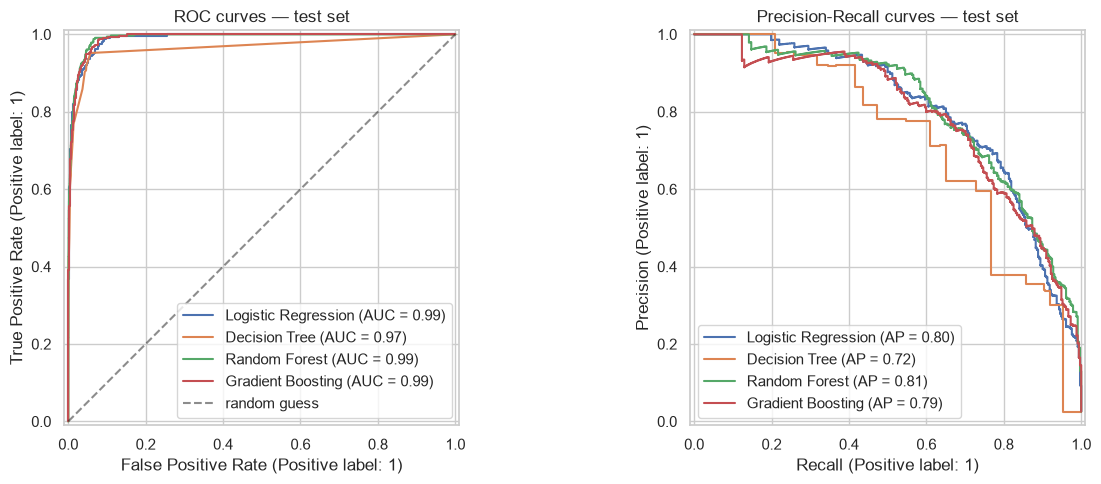

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, m in models.items():
    RocCurveDisplay.from_predictions(y_test, test_prob[name], name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, test_prob[name], name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5, label="random guess")
axes[0].set_title("ROC curves — test set"); axes[0].legend(loc="lower right")
axes[1].set_title("Precision-Recall curves — test set")
plt.tight_layout(); plt.show()

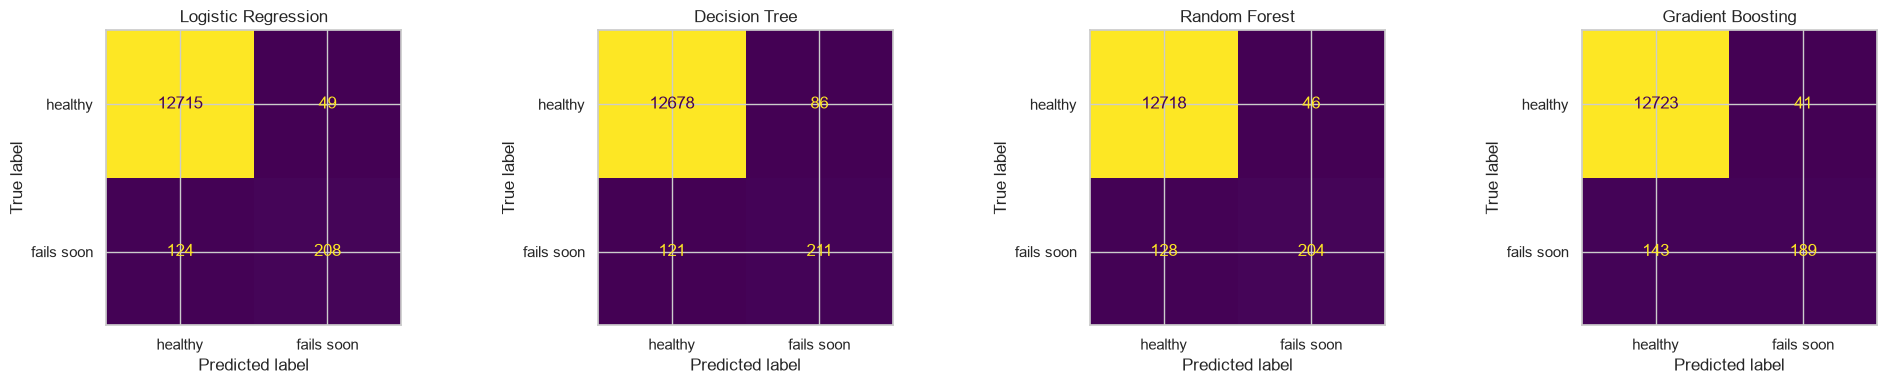

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (name, p) in zip(axes, test_prob.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, (p >= 0.5).astype(int), display_labels=["healthy", "fails soon"],
                                            ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

## 6. Why is test recall lower than in cross-validation?

In cross-validation the models caught about 85% of "fails soon" rows, but on the test set noticeably fewer. Let's look at **where** the mistakes happen.

In [9]:
best_name = cv_table["val_f1"].idxmax()
print("Model with the best cross-validated F1:", best_name)

buckets = [-1, 10, 20, 25, 30]
labels = ["0–10", "11–20", "21–25", "26–30"]
pos_test = test[y_test == 1].copy()
pos_test["caught"] = (test_prob[best_name][y_test == 1] >= 0.5)
pos_test["RUL bucket"] = pd.cut(pos_test["RUL"], buckets, labels=labels)
by_bucket = pos_test.groupby("RUL bucket", observed=False).agg(rows=("caught", "size"), recall=("caught", "mean"))

train_share = pd.cut(train.loc[y_train == 1, "RUL"], buckets, labels=labels).value_counts(normalize=True).sort_index()
by_bucket["share of positives — test"] = by_bucket["rows"] / by_bucket["rows"].sum()
by_bucket["share of positives — train"] = train_share.values
by_bucket.round(3)

Model with the best cross-validated F1: Random Forest


,rows,recall,share of positives — test,share of positives — train
RUL bucket,,,,
0–10,17,1.000,0.051,0.355
11–20,106,0.896,0.319,0.323
21–25,95,0.600,0.286,0.161
26–30,114,0.307,0.343,0.161


In [10]:
fp_rul = test.loc[(y_test == 0) & (test_prob[best_name] >= 0.5), "RUL"]
print(f"False alarms: {len(fp_rul)} rows. Their true RUL: median {fp_rul.median():.0f}, "
      f"{(fp_rul <= 40).mean():.0%} have RUL ≤ 40 (i.e. within 10 cycles of the boundary)")

False alarms: 46 rows. Their true RUL: median 38, 57% have RUL ≤ 40 (i.e. within 10 cycles of the boundary)


**Interpretation — this is the key insight of the project:**
- The model is **excellent when failure is close**: it catches 100% of rows with RUL 0–10 and ≈90% with RUL 11–20.
  It struggles at **RUL 21–30** (≈60% and ≈31%), right next to the 30-cycle boundary. There, an engine with 29 cycles left looks almost identical to one with 31 — the label boundary is sharp, but wear is gradual.
- In the **test set ≈63% of the positive rows are these hard RUL 21–30 cases, versus ≈32% in training**, because test engines are cut off before failure. That alone explains most of the drop in recall — it is a property of the test set, not a broken model.
- The **false alarms** are mostly "early warnings": their median true RUL is ≈38, and more than half are within 10 cycles of the boundary. In practice, inspecting an engine a few cycles early is cheap compared with missing a failure.

## 7. Threshold tuning — catching more failures

By default a model predicts "fails soon" when the probability ≥ **0.5**. In maintenance, a **missed failure costs far more** than an extra inspection,
so it is reasonable to **lower the threshold**: flag an engine when the probability is lower → recall goes up, precision goes down.

**How we choose the threshold without cheating:** we use **out-of-fold** predictions on the *training* engines (`cross_val_predict` with GroupKFold — every training row is predicted by a model that did not see its engine),
and pick the **highest threshold that gives at least 90% recall**. The test set is then evaluated with that fixed threshold.

Random Forest: highest threshold with ≥90% cross-validated recall = 0.334


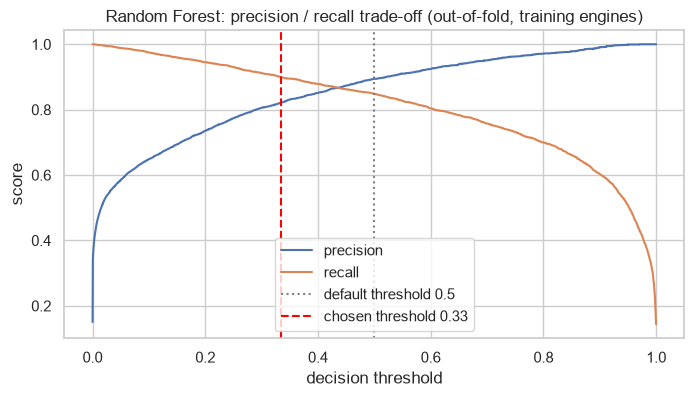

In [11]:
TARGET_RECALL = 0.90
oof_prob = cross_val_predict(models[best_name], X_train, y_train, groups=groups, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof_prob)
ok = rec[:-1] >= TARGET_RECALL
best_threshold = float(thr[ok].max())
print(f"{best_name}: highest threshold with ≥{TARGET_RECALL:.0%} cross-validated recall = {best_threshold:.3f}")

plt.figure(figsize=(8, 4))
plt.plot(thr, prec[:-1], label="precision")
plt.plot(thr, rec[:-1], label="recall")
plt.axvline(0.5, color="grey", linestyle=":", label="default threshold 0.5")
plt.axvline(best_threshold, color="red", linestyle="--", label=f"chosen threshold {best_threshold:.2f}")
plt.xlabel("decision threshold"); plt.ylabel("score"); plt.legend()
plt.title(f"{best_name}: precision / recall trade-off (out-of-fold, training engines)")
plt.show()

In [12]:
compare_thr = pd.DataFrame([
    test_metrics(f"{best_name} @ 0.5", y_test, test_prob[best_name], 0.5),
    test_metrics(f"{best_name} @ {best_threshold:.2f}", y_test, test_prob[best_name], best_threshold),
]).set_index("model")
compare_thr.round(3)

,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,,
Random Forest @ 0.5,0.500,0.987,0.816,0.614,0.701,0.991,0.807
Random Forest @ 0.33,0.334,0.986,0.729,0.720,0.724,0.991,0.807


**Interpretation:** lowering the threshold from 0.5 to ≈0.33 **raises test recall from ≈0.61 to ≈0.72** (fewer missed failures) at the cost of some precision (≈0.82 → ≈0.73, more early inspections); F1 even improves slightly.
ROC-AUC and PR-AUC do not change — the model's *ranking* is the same; we only moved the cut-off.
**Choosing the threshold is a business decision**: it depends on how much a missed failure costs compared with an extra inspection.

## 8. Realistic evaluation: one decision per engine

In real life the question at any moment is: **"Given everything we know about this engine *right now*, should it go for maintenance?"**
For each of the 100 test engines we take its **last available cycle** and make one prediction. 25 of the 100 engines were truly within 30 cycles of failure.

In [13]:
last_idx = test.groupby("unit")["cycle"].idxmax()
y_last = y_test.loc[last_idx]
print("Engines that truly need maintenance:", int(y_last.sum()), "of", len(y_last))

engine_rows = []
for name, m in models.items():
    p_last = m.predict_proba(X_test.loc[last_idx])[:, 1]
    engine_rows.append(test_metrics(name, y_last, p_last, 0.5))
p_last_best = models[best_name].predict_proba(X_test.loc[last_idx])[:, 1]
engine_rows.append(test_metrics(f"{best_name} @ {best_threshold:.2f}", y_last, p_last_best, best_threshold))
engine_table = pd.DataFrame(engine_rows).set_index("model")
engine_table.round(3)

Engines that truly need maintenance: 25 of 100


,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,,
Logistic Regression,0.500,0.92,0.947,0.72,0.818,0.985,0.960
Decision Tree,0.500,0.91,0.944,0.68,0.791,0.918,0.860
Random Forest,0.500,0.91,0.944,0.68,0.791,0.984,0.957
Gradient Boosting,0.500,0.91,0.944,0.68,0.791,0.977,0.929
Random Forest @ 0.33,0.334,0.92,0.947,0.72,0.818,0.984,0.957


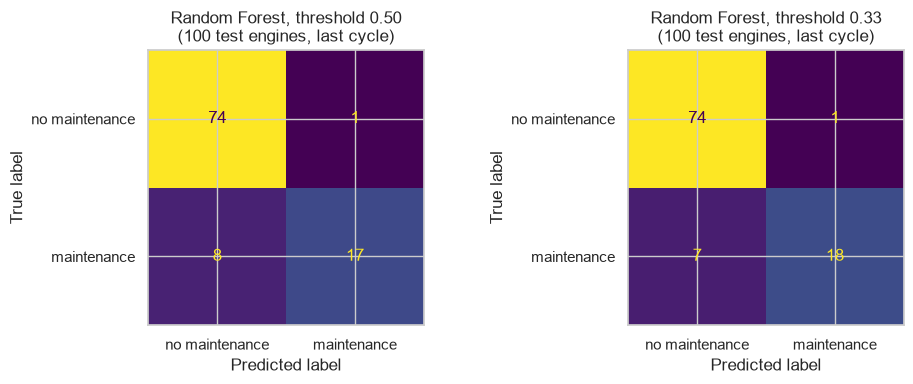

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, t in zip(axes, [0.5, best_threshold]):
    ConfusionMatrixDisplay.from_predictions(y_last, (p_last_best >= t).astype(int),
                                            display_labels=["no maintenance", "maintenance"], ax=ax, colorbar=False)
    ax.set_title(f"{best_name}, threshold {t:.2f}\n(100 test engines, last cycle)")
plt.tight_layout(); plt.show()

In [15]:
# Which engines were missed / falsely flagged, and how far from failure were they really?
decisions = pd.DataFrame({
    "unit": test.loc[last_idx, "unit"].values,
    "true_RUL": test.loc[last_idx, "RUL"].values,
    "needs_maintenance": y_last.values,
    "probability": p_last_best.round(3),
    "flagged": (p_last_best >= best_threshold).astype(int),
})
missed = decisions[(decisions["needs_maintenance"] == 1) & (decisions["flagged"] == 0)]
false_alarm = decisions[(decisions["needs_maintenance"] == 0) & (decisions["flagged"] == 1)]
print("Missed engines (true RUL ≤ 30 but not flagged):")
print(missed.sort_values("true_RUL").to_string(index=False))
print("\nFalse alarms (flagged but true RUL > 30):")
print(false_alarm.sort_values("true_RUL").to_string(index=False))

Missed engines (true RUL ≤ 30 but not flagged):
 unit  true_RUL  needs_maintenance  probability  flagged
   41        18                  1        0.204        0
   37        21                  1        0.240        0
   61        21                  1        0.228        0
   53        26                  1        0.153        0
   64        28                  1        0.287        0
   18        28                  1        0.045        0
   52        29                  1        0.287        0

False alarms (flagged but true RUL > 30):
 unit  true_RUL  needs_maintenance  probability  flagged
   91        38                  0        0.861        1


**Interpretation:** with one decision per engine, the model is **very precise** — almost every engine it sends to maintenance really needed it.
At threshold ≈0.33 it flagged 19 engines: 18 truly needed maintenance and the single false alarm had 38 cycles left — an early warning, not a wild mistake.
The 7 missed engines all had **18–29 cycles left** — the upper end of the 30-cycle window. **Every engine with fewer than 18 cycles left was caught.**
In practice those missed engines would very likely be flagged a few cycles later, at their next check, still before failure.

## 9. Which features matter most? (Random Forest)

**Impurity-based importance** = how much each feature reduced Gini impurity, summed over all splits in all trees (normalised to sum to 1).

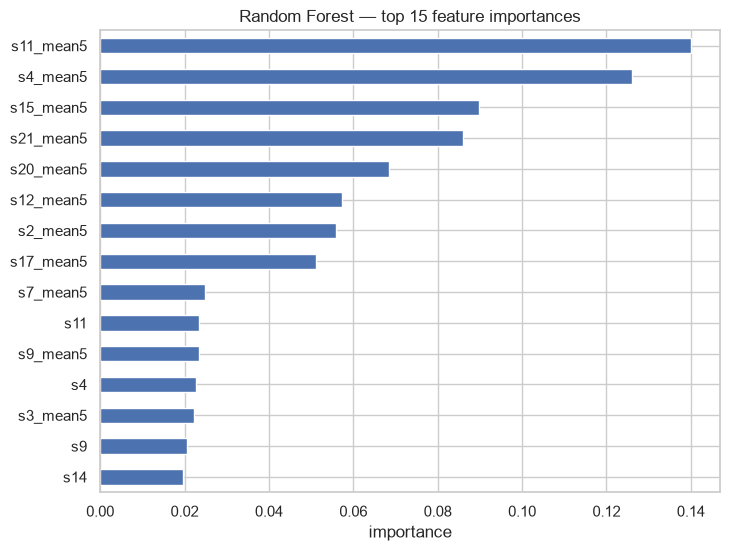

rolling mean    0.779
raw sensor      0.174
rolling std     0.047
Name: total importance by feature type, dtype: float64

In [16]:
imp = pd.Series(rf_best.feature_importances_, index=feature_cols).sort_values(ascending=False)
plt.figure(figsize=(8, 6))
imp.head(15)[::-1].plot(kind="barh")
plt.title("Random Forest — top 15 feature importances")
plt.xlabel("importance")
plt.show()
kinds = pd.Series({c: ("rolling mean" if c.endswith("_mean5") else "rolling std" if c.endswith("_std5") else "raw sensor")
                   for c in feature_cols})
imp.groupby(kinds).sum().sort_values(ascending=False).round(3).rename("total importance by feature type")

**Interpretation:** the **rolling-mean features dominate** — together they carry most of the importance, far more than the raw readings.
This is direct evidence that the **feature derivation** step (Notebook 3) was worthwhile. The rolling-std features carry very little — engine instability turned out to be a weak signal compared with the level of the smoothed readings.

## 10. Final comparison and conclusion

In [17]:
final = pd.DataFrame({
    "CV F1": cv_table["val_f1"],
    "CV recall": cv_table["val_recall"],
    "CV ROC-AUC": cv_table["val_roc_auc"],
    "Test F1": test_table["f1"],
    "Test recall": test_table["recall"],
    "Test precision": test_table["precision"],
    "Test ROC-AUC": test_table["roc_auc"],
    "Test PR-AUC": test_table["pr_auc"],
    "Engine-level recall": engine_table.loc[list(models), "recall"],
    "Engine-level precision": engine_table.loc[list(models), "precision"],
}).round(3)
os.makedirs("../results", exist_ok=True)
final.to_csv("../results/final_comparison.csv")
joblib.dump(rf_best, "../models/random_forest.joblib")
joblib.dump(gb_best, "../models/gradient_boosting.joblib")
final

,CV F1,CV recall,CV ROC-AUC,Test F1,Test recall,Test precision,Test ROC-AUC,Test PR-AUC,Engine-level recall,Engine-level precision
model,,,,,,,,,,
Logistic Regression,0.866,0.865,0.990,0.706,0.627,0.809,0.989,0.803,0.72,0.947
Decision Tree,0.859,0.848,0.982,0.671,0.636,0.710,0.966,0.724,0.68,0.944
Random Forest,0.871,0.848,0.990,0.701,0.614,0.816,0.991,0.807,0.68,0.944
Gradient Boosting,0.866,0.837,0.990,0.673,0.569,0.822,0.990,0.788,0.68,0.944


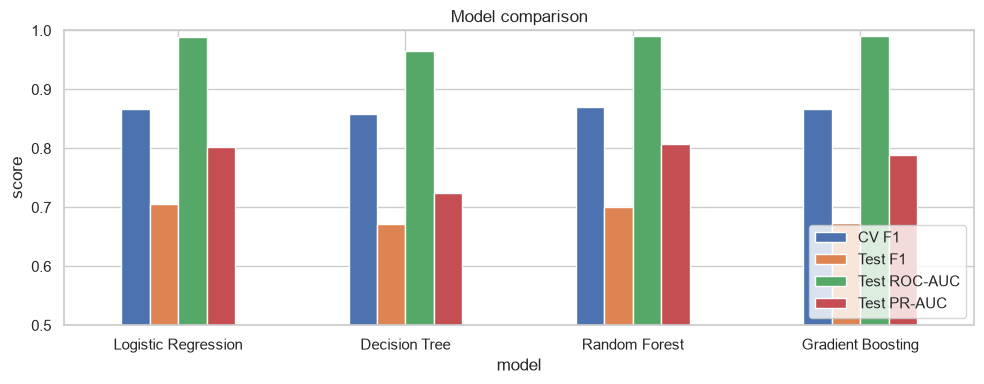

In [18]:
ax = final[["CV F1", "Test F1", "Test ROC-AUC", "Test PR-AUC"]].plot(kind="bar", figsize=(10, 4), rot=0)
ax.set_ylim(0.5, 1.0); ax.set_ylabel("score"); ax.set_title("Model comparison")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

### Conclusion

1. **All four models learned the problem well** — test ROC-AUC 0.97–0.99, i.e. they rank a failing engine above a healthy one almost every time.
2. **Regularization mattered most for the Decision Tree**: the unlimited tree overfit (train F1 1.000 vs validation 0.815); limiting depth/leaf size raised validation F1 to 0.859 and ROC-AUC from 0.894 to 0.982.
3. **Ensembles:** the Random Forest fixed the single tree's overfitting (validation F1 0.871 vs 0.859, test PR-AUC 0.807 vs 0.724) and is the **best model in cross-validation** (highest F1) and on the test set by ROC-AUC and PR-AUC. Gradient Boosting was competitive but not better here.
4. **Logistic regression is surprisingly close** (validation F1 0.866, test PR-AUC 0.803): after feature derivation the smoothed sensor levels simply rise or fall with wear, so the classes are almost linearly separable. The differences between the top three models are smaller than the fold-to-fold variation.
5. **Final model: Random Forest with threshold ≈0.33** — best overall scores, robust to the overfitting a single tree suffers from, and the lowered threshold catches more failing engines. **Logistic regression is a near-equal, simpler alternative** if explainability is the priority.
6. **The hardest cases are engines 21–35 cycles from failure** — the label boundary is sharp but wear is gradual. This, not model weakness, explains the lower test recall: the test set contains twice the share of these boundary cases.
7. **The derived rolling-mean features carry ≈78% of the Random Forest's importance** — feature derivation was the single most valuable step.

### Limitations
- Data is **simulated** (high-fidelity NASA model) — real engines have more noise, missing data and maintenance history.
- Only **FD001**: one operating condition and one fault mode. FD002–FD004 would need operating-condition normalisation.
- The **30-cycle window** is a design choice; a different window changes the problem.
- Rows of the same engine are not independent, so row-level scores are optimistic about how "many" distinct cases we tested — the engine-level evaluation (100 decisions) is the most honest view.

### Possible extensions
- Predict the exact **RUL** with regression; try sequence models (LSTM) on raw time series.
- Apply the pipeline to **FD002–FD004**.
- Choose the threshold from a **cost model** (cost of a missed failure vs. cost of an inspection).

## Likely viva questions
- *What is the difference between bagging and boosting?* → Bagging trains trees independently on bootstrap samples and averages them (reduces variance); boosting trains trees one after another, each correcting the previous errors (reduces bias).
- *Why does Random Forest overfit less than one tree?* → Its trees are decorrelated (bootstrap rows + random features), so their individual errors partly cancel when averaged.
- *Can adding more trees to a Random Forest cause overfitting?* → No — more trees only make the average more stable; it costs computation time.
- *Why is accuracy not used to compare models?* → Only 2.5% of test rows are positive; predicting "healthy" always would score 97.5% accuracy.
- *Why does the test recall differ from cross-validation?* → The test set contains a much larger share of hard boundary cases (RUL 21–30) because engines are cut off before failure.
- *How did you choose the threshold without using the test set?* → From out-of-fold predictions on the training engines (GroupKFold), targeting 90% recall.
- *ROC-AUC vs PR-AUC?* → ROC-AUC can look good even when the rare class is handled poorly; PR-AUC focuses on the rare (positive) class, so it is more informative under imbalance.
- *Which model would you deploy and why?* → Random Forest with a lowered threshold (≈0.33): best cross-validated F1 and best test ROC/PR-AUC, no single-tree overfitting, and the threshold raises recall. Logistic regression is a near-equal, more explainable alternative.
- *Why didn't Gradient Boosting win?* → With strong, smooth features the problem is nearly linear; boosting's strength (correcting subtle errors step by step) has little left to fix, and the remaining errors are boundary cases that no model can separate well. Its CV F1 (0.866) is within the fold-to-fold noise of the others.